# 01 · Segment the document from its outline

The PDF outline (bookmarks) gives the exact page **and y position** of every `CS-E X`, `AMC E X…` and appendix heading. A section runs from its heading down to the next outline heading (any level), so text can never leak into the section before or after it.

* Level 1 = subpart, level 2 = `CS-E X` (+ `AMC General`), level 3 = `AMC E X…` / `Appendix A`.
* `group_id` links an AMC to its CS-E (e.g. `AMC E 20(f)` → `CS-E 20`).
* Pages 1–15 (Table of Contents, Preamble) are skipped.

Output: `data/sections.json` (section metadata + page regions; no text yet).

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)  # all paths below are relative to the repo root
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
PDF = ROOT / "cs-e_amendment_9.pdf"   # header/footer already cropped
DATA = ROOT / "data"

In [2]:
import pandas as pd, pymupdf
from csparse.segment import FIRST_BODY_PAGE, build_sections, coverage_report, outline_boundaries, region_text, save_sections

doc = pymupdf.open(PDF)
pd.set_option("display.max_rows", 200, "display.max_colwidth", 80)
print(doc.page_count, "pages; first body page:", FIRST_BODY_PAGE)

268 pages; first body page: 16


### Outline headings and their snapped positions
`outline_y` is where the bookmark points; `y` is the top of the heading's text line (the boundary actually used). `matched` must never be empty.

In [3]:
bounds = pd.DataFrame([b.__dict__ for b in outline_boundaries(doc)])
bounds["shift"] = (bounds.y - bounds.outline_y).round(1)
print("headings:", len(bounds), "| not matched to a text line:", bounds.matched.isna().sum())
bounds.head(15)

headings: 181 | not matched to a text line: 0


,level,title,page,y,outline_y,matched,shift
0,1,SUBPART A – GENERAL,16,13.410002,10.280029,SUBPART A – GENERAL,3.1
1,2,AMC General,16,54.990021,40.280030,AMC General,14.7
2,2,CS-E 10 Applicability,16,119.430023,105.280030,CS-E 10 Applicability,14.1
3,3,AMC E 10(b) Thrust Reversers,16,331.020020,310.280040,AMC E 10(b) Thrust Reversers,20.7
4,2,CS-E 15 Terminology,17,180.390045,160.280030,CS-E 15 Terminology,20.1
5,2,CS-E 20 Engine Configuration and Interfaces,19,279.180023,259.280040,CS-E 20 Engine Configuration and Interfaces,19.9
6,3,AMC E 20 Engine Configuration and Interfaces,20,12.630036,10.280029,AMC E 20 Engine Configuration and Interfaces,2.4
7,3,AMC E 20(f) Power Assurance Data for Engines with One or More OEI Power Ratings,21,12.510041,10.280029,AMC E 20(f) Power Assurance Data for Engines with One or More,2.2
8,2,CS-E 25 Instructions for Continued Airworthiness,22,128.190033,108.280030,CS-E 25 Instructions for Continued Airworthiness,19.9
9,3,AMC E 25 Instructions for continued airworthiness,23,489.800018,469.280040,AMC E 25 Instructions for continued airworthiness,20.5


In [4]:
sections = build_sections(doc)
rows = []
for s in sections:
    rows.append(dict(order=s.order, section_id=s.section_id, kind=s.kind, group_id=s.group_id, subpart=s.subpart,
                     pages=f"{s.page_start}-{s.page_end}", n_regions=len(s.regions),
                     native_chars=sum(len(region_text(doc, r)) for r in s.regions), heading=s.heading))
df = pd.DataFrame(rows)
print(len(df), "sections;", df.kind.value_counts().to_dict())
df

175 sections; {'cs': 91, 'amc': 82, 'amc_general': 1, 'appendix': 1}


,order,section_id,kind,group_id,subpart,pages,n_regions,native_chars,heading
0,0,AMC General (SUBPART A),amc_general,SUBPART A,SUBPART A,16-16,1,212,General
1,1,CS-E 10,cs,CS-E 10,SUBPART A,16-16,1,709,Applicability
2,2,AMC E 10(b),amc,CS-E 10,SUBPART A,16-17,2,2737,Thrust Reversers
3,3,CS-E 15,cs,CS-E 15,SUBPART A,17-19,3,7185,Terminology
4,4,CS-E 20,cs,CS-E 20,SUBPART A,19-20,2,1941,Engine Configuration and Interfaces
5,5,AMC E 20,amc,CS-E 20,SUBPART A,20-21,2,3275,Engine Configuration and Interfaces
6,6,AMC E 20(f),amc,CS-E 20,SUBPART A,21-22,2,4400,Power Assurance Data for Engines with One or More OEI Power Ratings
7,7,CS-E 25,cs,CS-E 25,SUBPART A,22-23,2,4933,Instructions for Continued Airworthiness
8,8,AMC E 25,amc,CS-E 25,SUBPART A,23-28,6,16231,Instructions for continued airworthiness
9,9,CS-E 30,cs,CS-E 30,SUBPART A,28-28,1,941,Assumptions


### Coverage check
Every text line of pages 16–268 must belong to exactly one section. The only allowed orphans are the subpart title lines (and an `[Amdt]` note right under one of them).

In [5]:
rep = coverage_report(doc, sections)
print("overlaps:", len(rep["overlaps"]))
pd.DataFrame(rep["orphans"], columns=["page", "y", "text"])

overlaps: 0


,page,y,text
0,16,13.9,SUBPART A – GENERAL
1,67,16.2,SUBPART B — PISTON ENGINES: DESIGN AND
2,67,40.7,CONSTRUCTION
3,71,16.2,SUBPART C — PISTON ENGINES: TYPE
4,71,40.7,SUBSTANTIATION
5,71,69.3,[Amdt No: E/9]
6,84,16.2,SUBPART D – TURBINE ENGINES: DESIGN AND
7,84,40.7,CONSTRUCTION
8,119,16.2,SUBPART E – TURBINE ENGINES: TYPE
9,119,40.7,SUBSTANTIATION


### Groups (CS-E + its AMCs)

In [6]:
groups = df.groupby("group_id", sort=False).agg(sections=("section_id", list), pages=("pages", lambda p: f"{p.iloc[0].split('-')[0]}-{p.iloc[-1].split('-')[1]}"))
print(len(groups), "groups")
groups.head(20)

92 groups


,sections,pages
group_id,,
SUBPART A,[AMC General (SUBPART A)],16-16
CS-E 10,"[CS-E 10, AMC E 10(b)]",16-17
CS-E 15,[CS-E 15],17-19
CS-E 20,"[CS-E 20, AMC E 20, AMC E 20(f)]",19-22
CS-E 25,"[CS-E 25, AMC E 25]",22-28
CS-E 30,"[CS-E 30, AMC E 30]",28-30
CS-E 40,"[CS-E 40, AMC E 40, AMC E 40(b)(3) and (b)(4), AMC E 40(d)]",30-35
CS-E 50,"[CS-E 50, AMC E 50, AMC E 50(e), AMC E 50(j), AMC to CS-E 50(l)]",35-40
CS-E 60,"[CS-E 60, AMC E 60, AMC E 60(d)]",40-43


### Visual check: section boundaries drawn on a page

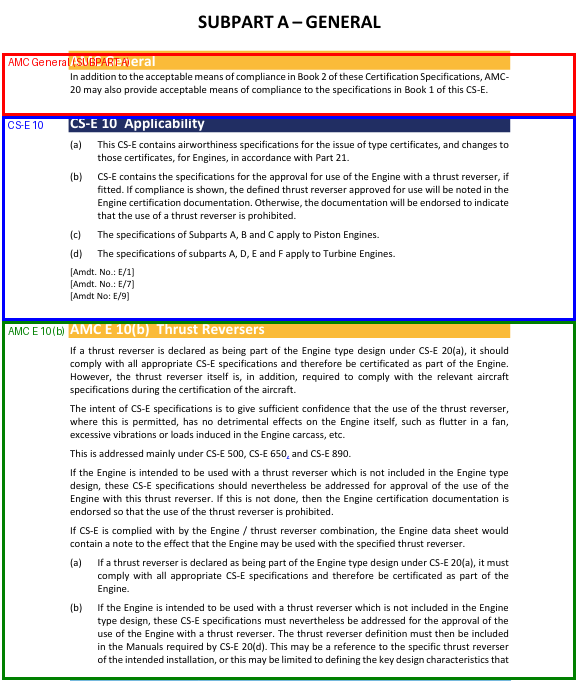

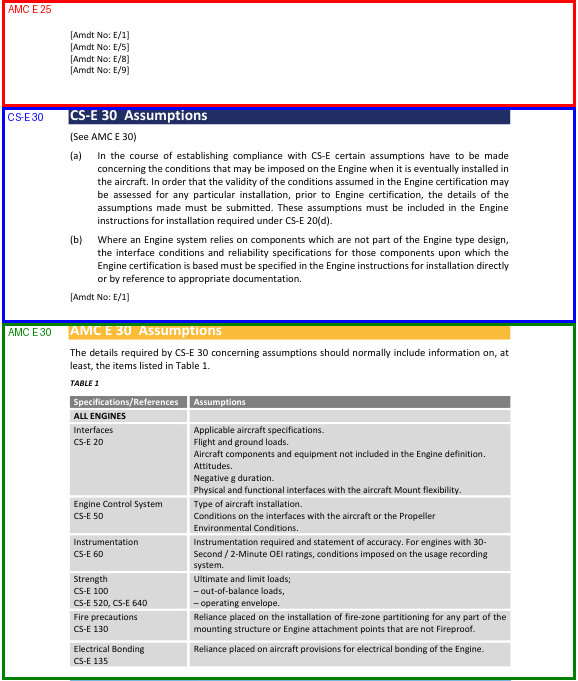

In [7]:
from PIL import Image as PILImage, ImageDraw
from IPython.display import display

def show_boundaries(page_no, dpi=70):
    page = doc[page_no - 1]
    pix = page.get_pixmap(dpi=dpi)
    img = PILImage.frombytes("RGB", (pix.width, pix.height), pix.samples)
    d = ImageDraw.Draw(img)
    k = dpi / 72
    colors = ["red", "blue", "green", "orange", "purple"]
    for i, s in enumerate([s for s in sections if any(r.page == page_no for r in s.regions)]):
        for r in s.regions:
            if r.page == page_no:
                d.rectangle([2, r.y0 * k, img.width - 3, r.y1 * k - 1], outline=colors[i % 5], width=3)
                d.text((8, r.y0 * k + 3), s.section_id, fill=colors[i % 5])
    display(img)

show_boundaries(16)
show_boundaries(28)

In [8]:
save_sections(sections, DATA / "sections.json")
print("wrote", DATA / "sections.json")

wrote /home/goksu/projects/ikincitik/data/sections.json
